In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("powerplant_data.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
#AT = TEMP
#V = VACCUM
#AP = PRESSURE
#RH = HUMIDITY
#PE = PRODUCED ENERGY -> OUTPUT

In [5]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [6]:
X = df.drop("PE", axis=1)
y = df["PE"]

In [7]:
X

,AT,V,AP,RH
0,8.34,40.77,1010.84,90.01
1,23.64,58.49,1011.40,74.20
2,29.74,56.90,1007.15,41.91
3,19.07,49.69,1007.22,76.79
4,11.80,40.66,1017.13,97.20
...,...,...,...,...
9563,15.12,48.92,1011.80,72.93
9564,33.41,77.95,1010.30,59.72
9565,15.99,43.34,1014.20,78.66
9566,17.65,59.87,1018.58,94.65


In [8]:
y

0       480.48
1       445.75
2       438.76
3       453.09
4       464.43
         ...  
9563    462.59
9564    432.90
9565    465.96
9566    450.93
9567    451.67
Name: PE, Length: 9568, dtype: float64

In [9]:
#split out data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [11]:
import torch
import torch.nn as nn

In [12]:
type(X_train_scaled)

numpy.ndarray

In [13]:
type(y_train)

pandas.core.series.Series

In [14]:
y_train.shape

(7654,)

In [15]:
X_train_tensors = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensors = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensors = torch.tensor(y_train.values, dtype=torch.float32).view(-1,1) 
# values because we didn't scaled this data
# y_train shape is now [1,2,3..] but we want it to be [[1],
#                                                       [2],
#                                                        .
#                                                        .
#                                                         ]
# that's why view(rows, cols) -> -1 means auto detect rows

y_test_tensors = torch.tensor(y_test.values, dtype=torch.float32).view(-1,1)

In [16]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensors, y_train_tensors)
test_dataset = TensorDataset(X_test_tensors, y_test_tensors)

In [17]:
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=True)

# Deep Learning

In [18]:
#define ANN model
class ANN(nn.Module):
    def __init__(self):
        super(ANN, self).__init__()

        self.model = nn.Sequential(
            #1st hidden layer
            nn.Linear(X_train.shape[1], 6), # (in_feat, out_feat)
            nn.ReLU(),
    
            #2nd hidden layer
            nn.Linear(6, 6),
            nn.ReLU(),
    
            #output layer
            nn.Linear(6,1),
        )

    def forward(self,x):
        return self.model(x)

In [19]:
import torch.optim as optim

model = ANN()

#loss, optimizer
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [20]:
# Train the ANN
train_losses = []
val_losses = []

best_val_loss = float('inf')

epochs = 100

for epoch in range(epochs):

    model.train()
    running_loss = 0.0

    for xb, yb in train_loader:

        optimizer.zero_grad()

        outputs = model(xb)

        loss = criterion(outputs, yb)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_train_loss = running_loss / len(train_loader)

    train_losses.append(epoch_train_loss)

    # Validation
    model.eval()

    running_val_loss = 0.0

    with torch.no_grad():

        for xb, yb in test_loader:

            outputs = model(xb)

            loss = criterion(outputs, yb)

            running_val_loss += loss.item()

    epoch_val_loss = running_val_loss / len(test_loader)

    val_losses.append(epoch_val_loss)

    print(f"Epoch {epoch+1}/{epochs} ==> Train Loss = {epoch_train_loss:.4f} & Val Loss = {epoch_val_loss:.4f}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt") #pt or pth

Epoch 1/100 ==> Train Loss = 206089.7200 & Val Loss = 203402.4630
Epoch 2/100 ==> Train Loss = 193280.0919 & Val Loss = 177343.7755
Epoch 3/100 ==> Train Loss = 150946.3802 & Val Loss = 120591.2060
Epoch 4/100 ==> Train Loss = 88926.7247 & Val Loss = 60305.4249
Epoch 5/100 ==> Train Loss = 41628.7670 & Val Loss = 28953.6420
Epoch 6/100 ==> Train Loss = 23891.3849 & Val Loss = 20353.1157
Epoch 7/100 ==> Train Loss = 18519.4462 & Val Loss = 16556.9591
Epoch 8/100 ==> Train Loss = 15113.7091 & Val Loss = 13250.3968
Epoch 9/100 ==> Train Loss = 11889.6250 & Val Loss = 10097.7047
Epoch 10/100 ==> Train Loss = 8835.1676 & Val Loss = 7223.3070
Epoch 11/100 ==> Train Loss = 6158.4202 & Val Loss = 4818.7148
Epoch 12/100 ==> Train Loss = 3983.9336 & Val Loss = 2985.6843
Epoch 13/100 ==> Train Loss = 2406.3968 & Val Loss = 1758.1516
Epoch 14/100 ==> Train Loss = 1417.0712 & Val Loss = 1059.7520
Epoch 15/100 ==> Train Loss = 862.8874 & Val Loss = 670.6541
Epoch 16/100 ==> Train Loss = 559.5268 & V

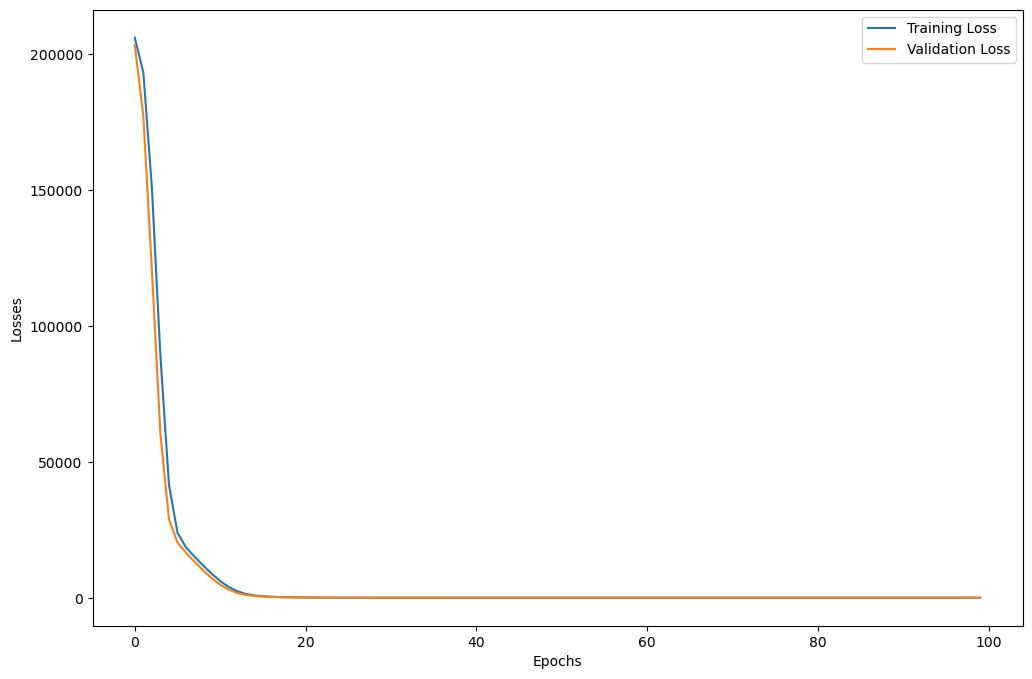

In [21]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss":train_losses,
    "Validation Loss":val_losses
})

plt.figure(figsize=(12,8))
plt.plot(loss_df["Training Loss"], label="Training Loss")
plt.plot(loss_df["Validation Loss"], label="Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [22]:
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [23]:
#Evaluation
model.eval()
with torch.no_grad():
    train_preds = model(X_train_tensors)
    test_preds = model(X_test_tensors)

    train_mse_loss = criterion(train_preds, y_train_tensors)
    test_mse_loss = criterion(test_preds, y_test_tensors)

print("Training MSE: ", train_mse_loss.item())
print("Testing MSE: ", test_mse_loss.item())

Training MSE:  20.085453033447266
Testing MSE:  18.492921829223633


In [24]:
from sklearn.metrics import r2_score

print("r^2 score: ", r2_score(y_test, test_preds))

r^2 score:  0.9353720089955906


In [25]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns=["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns=["Actual Values"])

result_df = pd.concat([actual_df, predicted_df], axis=1)

result_df

,Actual Values,Predicted Values
0,433.27,435.301270
1,438.16,436.795776
2,458.42,461.751648
3,480.82,476.680176
4,441.41,435.540710
...,...,...
1909,456.70,451.399780
1910,438.04,431.575745
1911,467.80,467.780151
1912,437.14,430.978760
